# Laboratorio · Análisis de datos de entrada
**Simulación Computacional – Unillanos** · guía FO-DOC-112 (Práctica: análisis de datos de entrada y ajuste de distribuciones)

Este notebook cubre:
- **5.1** Estadística descriptiva + histogramas (20 bins)
- **5.2** Supuestos: independencia (lag correlations, scatter) y estabilidad (arrival time pattern, conteos por intervalo, media móvil), más pruebas numéricas de apoyo

El ajuste de curvas (**5.3**) está en el notebook independiente `Lab_Ajuste_Curvas.ipynb`, como pide la guía.
Las figuras y tablas se guardan en `imagenes/` y `tablas/` para el informe (`main.tex`).

## 0. Librerías y datos

In [1]:
import numpy as np
import pandas as pd
import scipy.stats as st
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

IMG = Path('imagenes'); TAB = Path('tablas')        # salidas que usa el informe (main.tex)
IMG.mkdir(exist_ok=True); TAB.mkdir(exist_ok=True)

Carga de los 4 datasets desde los archivos `dataset-A.txt`, `dataset-B.txt`, `dataset-C.txt` y `dataset-D.txt`.
Mantén estos archivos en la misma carpeta que este notebook.

In [2]:
DATA_DIR = Path.cwd()
dataset_paths = {k: DATA_DIR / f'dataset-{k}.txt' for k in 'ABCD'}
missing = [str(path) for path in dataset_paths.values() if not path.is_file()]
if missing:
    raise FileNotFoundError(f'No se encontraron los datasets: {", ".join(missing)}')

data = {k: np.loadtxt(path) for k, path in dataset_paths.items()}
for k, x in data.items():
    print(k, len(x), x[:5])

A 200 [0.02096387 0.08135139 0.15621898 0.14936908 0.19343316]
B 200 [0.15208743 0.03557552 0.80398992 0.00727986 0.03515142]
C 200 [ 1.61591162  0.92668079  1.16692015 16.67646195 19.67795514]
D 200 [0.46374712 0.21354032 8.45622774 8.12966888 1.36584955]


## 5.1 Estadística descriptiva

In [3]:
def describir(x):
    return {
        'Tamaño de la muestra': len(x),
        'Mínimo': np.min(x),
        'Máximo': np.max(x),
        'Media': np.mean(x),
        'Varianza': np.var(x, ddof=1),          # varianza muestral (n-1)
        'Desviación estándar': np.std(x, ddof=1),
        'Percentil 25% (Q1)': np.percentile(x, 25),
        'Percentil 50% (Q2, mediana)': np.percentile(x, 50),
        'Percentil 75% (Q3)': np.percentile(x, 75),
        # extra para la consulta previa (asimetría y curtosis)
        'Asimetría (skewness)': st.skew(x),
        'Curtosis (exceso)': st.kurtosis(x),
        'Coef. de variación (s/media)': np.std(x, ddof=1) / np.mean(x),
    }

tabla1 = pd.DataFrame({f'Dataset {k}': describir(x) for k, x in data.items()})
tabla1.style.format('{:.5g}')

,Dataset A,Dataset B,Dataset C,Dataset D
Tamaño de la muestra,200,200,200,200
Mínimo,0.020964,8.516e-05,0.92668,0.1115
Máximo,0.29897,1.5513,6669.9,17.967
Media,0.19504,0.20539,762.39,2.0605
Varianza,0.0019193,0.052481,8.5217e+05,5.413
Desviación estándar,0.04381,0.22909,923.13,2.3266
Percentil 25% (Q1),0.16384,0.046329,152.91,0.63429
"Percentil 50% (Q2, mediana)",0.19207,0.13768,455.56,1.4064
Percentil 75% (Q3),0.23011,0.29018,1028.6,2.5289
Asimetría (skewness),-0.28952,2.4064,2.4821,3.1596


In [4]:
def num_tex(v, cifras=4):
    # número en formato LaTeX con coma decimal (estilo del informe)
    if isinstance(v, (int, np.integer)) or float(v).is_integer() and abs(v) < 1e6:
        return f'${int(v)}$'
    s = f'{v:.{cifras}g}'
    if 'e' in s:
        m, e = s.split('e')
        return f'${m.replace(".", "{,}")}\\times10^{{{int(e)}}}$'
    return f'${s.replace(".", "{,}")}$'

# filas de la Tabla 1 para el informe
with open(TAB / 'tabla_descriptiva.tex', 'w', encoding='utf-8') as f:
    for medida, fila in tabla1.iterrows():
        f.write(medida.replace('%', '\\%') + ' & ' + ' & '.join(num_tex(v, 5) for v in fila) + ' \\\\\n')
print((TAB / 'tabla_descriptiva.tex').read_text(encoding='utf-8'))

Tamaño de la muestra & $200$ & $200$ & $200$ & $200$ \\
Mínimo & $0{,}020964$ & $8{,}516\times10^{-5}$ & $0{,}92668$ & $0{,}1115$ \\
Máximo & $0{,}29897$ & $1{,}5513$ & $6669{,}9$ & $17{,}967$ \\
Media & $0{,}19504$ & $0{,}20539$ & $762{,}39$ & $2{,}0605$ \\
Varianza & $0{,}0019193$ & $0{,}052481$ & $8{,}5217\times10^{5}$ & $5{,}413$ \\
Desviación estándar & $0{,}04381$ & $0{,}22909$ & $923{,}13$ & $2{,}3266$ \\
Percentil 25\% (Q1) & $0{,}16384$ & $0{,}046329$ & $152{,}91$ & $0{,}63429$ \\
Percentil 50\% (Q2, mediana) & $0{,}19207$ & $0{,}13768$ & $455{,}56$ & $1{,}4064$ \\
Percentil 75\% (Q3) & $0{,}23011$ & $0{,}29018$ & $1028{,}6$ & $2{,}5289$ \\
Asimetría (skewness) & $-0{,}28952$ & $2{,}4064$ & $2{,}4821$ & $3{,}1596$ \\
Curtosis (exceso) & $0{,}30901$ & $7{,}9741$ & $9{,}1009$ & $14{,}089$ \\
Coef. de variación (s/media) & $0{,}22462$ & $1{,}1154$ & $1{,}2108$ & $1{,}1291$ \\



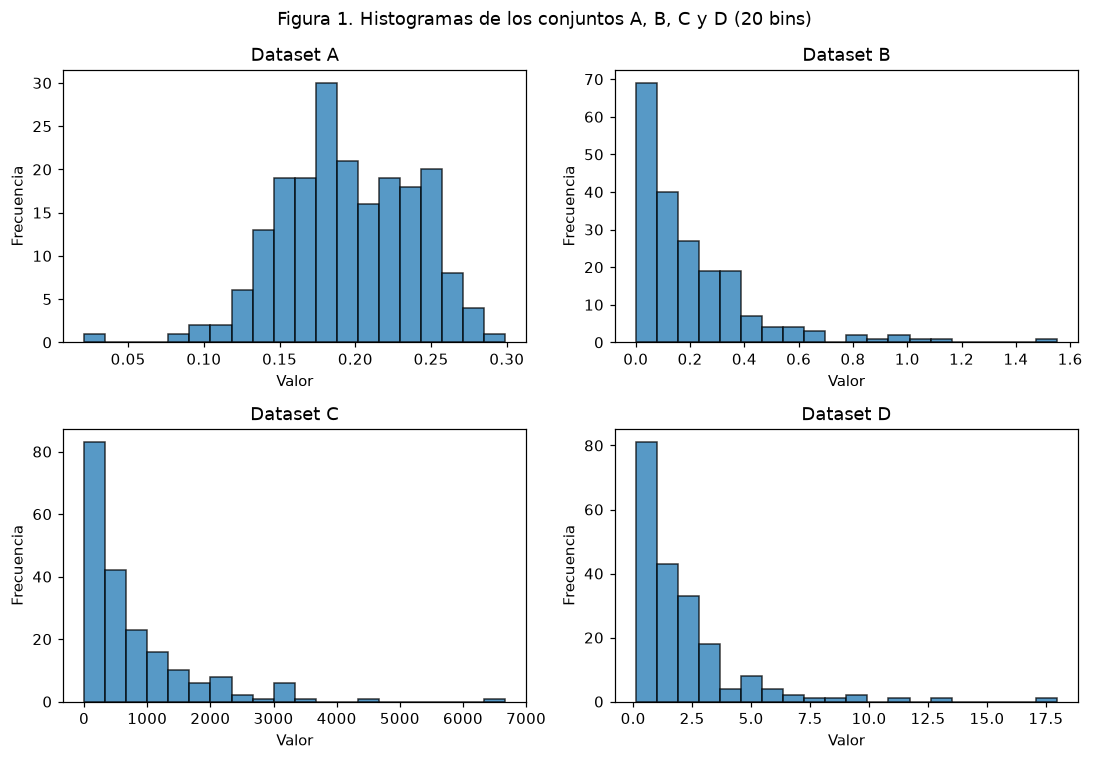

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
for ax, (k, x) in zip(axs.flat, data.items()):
    ax.hist(x, bins=20, edgecolor='black', alpha=0.75)
    ax.set_title(f'Dataset {k}')
    ax.set_xlabel('Valor'); ax.set_ylabel('Frecuencia')
fig.suptitle('Figura 1. Histogramas de los conjuntos A, B, C y D (20 bins)')
plt.tight_layout(); fig.savefig(IMG / 'histogramas.png', bbox_inches='tight'); plt.show()

### Análisis de 5.1
- **A** es el único conjunto casi simétrico: media 0,195 ≈ mediana 0,192, asimetría −0,29 y coeficiente de variación (CV) 0,22.
  Los valores están acotados en [0,021; 0,299] y el histograma tiene forma de campana. Esto apunta a una Normal o a una Gamma/Weibull
  con forma grande. El valor mínimo (0,021) está aislado del resto: es el primer dato de la serie (ver 5.2).
- **B** tiene media 0,205 > mediana 0,138, asimetría 2,41 y CV 1,12 ≈ 1. La moda está en cero y la frecuencia decae
  de forma monótona. Es el perfil típico de una exponencial.
- **C** tiene una escala completamente distinta (de 0,93 a 6670). Media 762 ≫ mediana 456, asimetría 2,48, curtosis 9,1 y CV 1,21 > 1.
  La cola derecha es más pesada que la de una exponencial.
- **D** tiene media 2,06 > mediana 1,41, asimetría 3,16 y la mayor curtosis (14,1), con CV 1,13. El mínimo (0,11) es mayor que cero
  y hay valores aislados hasta 18. Una cola tan larga es típica de una Lognormal o una Log-logística.
- A y B tienen casi la misma media (≈0,2) pero distribuciones opuestas: la media y la varianza no bastan para elegir un modelo de entrada.
  Todos los conjuntos son positivos, lo que pone en duda la Normal para B, C y D (daría probabilidad a tiempos negativos).

## 5.2 Análisis de supuestos (independencia y estabilidad)
Mismas gráficas del notebook *Example. Input Data Analysis*, reescritas para que no dependan de variables globales.
Los datos se interpretan como **tiempos entre llegadas** en el orden en que se observaron.

In [6]:
def lag_corr(x, k):
    # correlación entre pares (x_i, x_{i+k}) -> usa n-k pares
    return np.corrcoef(x[:-k], x[k:])[0, 1]

def plot_lag(ax, x, max_lag=20):
    lags = np.arange(1, max_lag + 1)
    r = [lag_corr(x, k) for k in lags]
    ax.bar(lags, r, width=0.6)
    b = 2 / np.sqrt(len(x))              # banda aprox. del 95% para datos independientes
    ax.axhline(b, ls='--', c='gray'); ax.axhline(-b, ls='--', c='gray'); ax.axhline(0, c='black', lw=0.8)
    ax.set_ylim(-1, 1); ax.set_title('Lag correlations'); ax.set_xlabel('lag k'); ax.set_ylabel('r_k')

def plot_scatter(ax, x):
    ax.scatter(x[:-1], x[1:], s=8, marker='^')
    ax.set_xlim(x.min(), x.max()); ax.set_ylim(x.min(), x.max())
    ax.set_title('Scatter diagram'); ax.set_xlabel('x_k'); ax.set_ylabel('x_{k+1}')

def plot_arrival_pattern(ax, x):
    t = np.cumsum(x)                          # instantes de llegada
    prop = np.arange(1, len(x) + 1) / len(x)  # proporción de llegadas antes de T
    ax.plot(t, prop, 'b'); ax.plot([0, t[-1]], [0, 1], 'k:', lw=0.8)
    ax.ticklabel_format(axis='x', style='sci', scilimits=(-3, 4))
    ax.set_title('Arrival time pattern'); ax.set_xlabel('Tiempo T'); ax.set_ylabel('Proporción antes de T')

def plot_arrival_counts(ax, x, nbins=40):
    t = np.cumsum(x)
    counts, edges = np.histogram(t, bins=nbins, range=(0, t[-1]))
    ax.bar(np.arange(1, nbins + 1), counts, width=1, edgecolor='black', color='white')
    ax.set_title(f'Arrival counts ({nbins} intervalos de {edges[1]:.3g})')
    ax.set_xlabel('Intervalo'); ax.set_ylabel('Conteo')

def moving_average(x, W):
    # y_k = (x_{k-W} + ... + x_k + ... + x_{k+W}) / (2W+1); en los extremos se usan menos puntos
    n = len(x)
    return np.array([x[max(0, k - W): min(n, k + W + 1)].mean() for k in range(n)])

def plot_moving_avg(ax, x, W=None):
    W = W or max(5, len(x) // 20)
    y = moving_average(x, W)
    m, s = y[W:-W].mean(), y[W:-W].std()
    ax.plot(y); ax.axhline(m, c='black')
    ax.axhline(m + 3 * s, c='green', ls='--'); ax.axhline(m - 3 * s, c='green', ls='--')
    ax.axvspan(0, W, color='gray', alpha=0.15); ax.axvspan(len(x) - W, len(x), color='gray', alpha=0.15)
    ax.set_title(f'Moving average (W={W}, ventana 2W+1={2*W+1})'); ax.set_xlabel('Posición k')

def plot_vs_order(ax, x):
    ax.plot(x, 'r.', ms=4); ax.set_title('Valores vs orden de ocurrencia'); ax.set_xlabel('k')

def analisis_supuestos(k, x):
    fig, axs = plt.subplots(2, 3, figsize=(14, 7.5))
    plot_vs_order(axs[0, 0], x)
    plot_lag(axs[0, 1], x)
    plot_scatter(axs[0, 2], x)
    plot_arrival_pattern(axs[1, 0], x)
    plot_arrival_counts(axs[1, 1], x)
    plot_moving_avg(axs[1, 2], x)
    fig.suptitle(f'Dataset {k}: independencia y estabilidad'); plt.tight_layout()
    fig.savefig(IMG / f'supuestos_{k}.png', bbox_inches='tight'); plt.show()
    print('lag 1..5:', np.round([lag_corr(x, j) for j in range(1, 6)], 3),
          '| banda ±2/sqrt(n) =', round(2 / np.sqrt(len(x)), 3))

### Dataset A

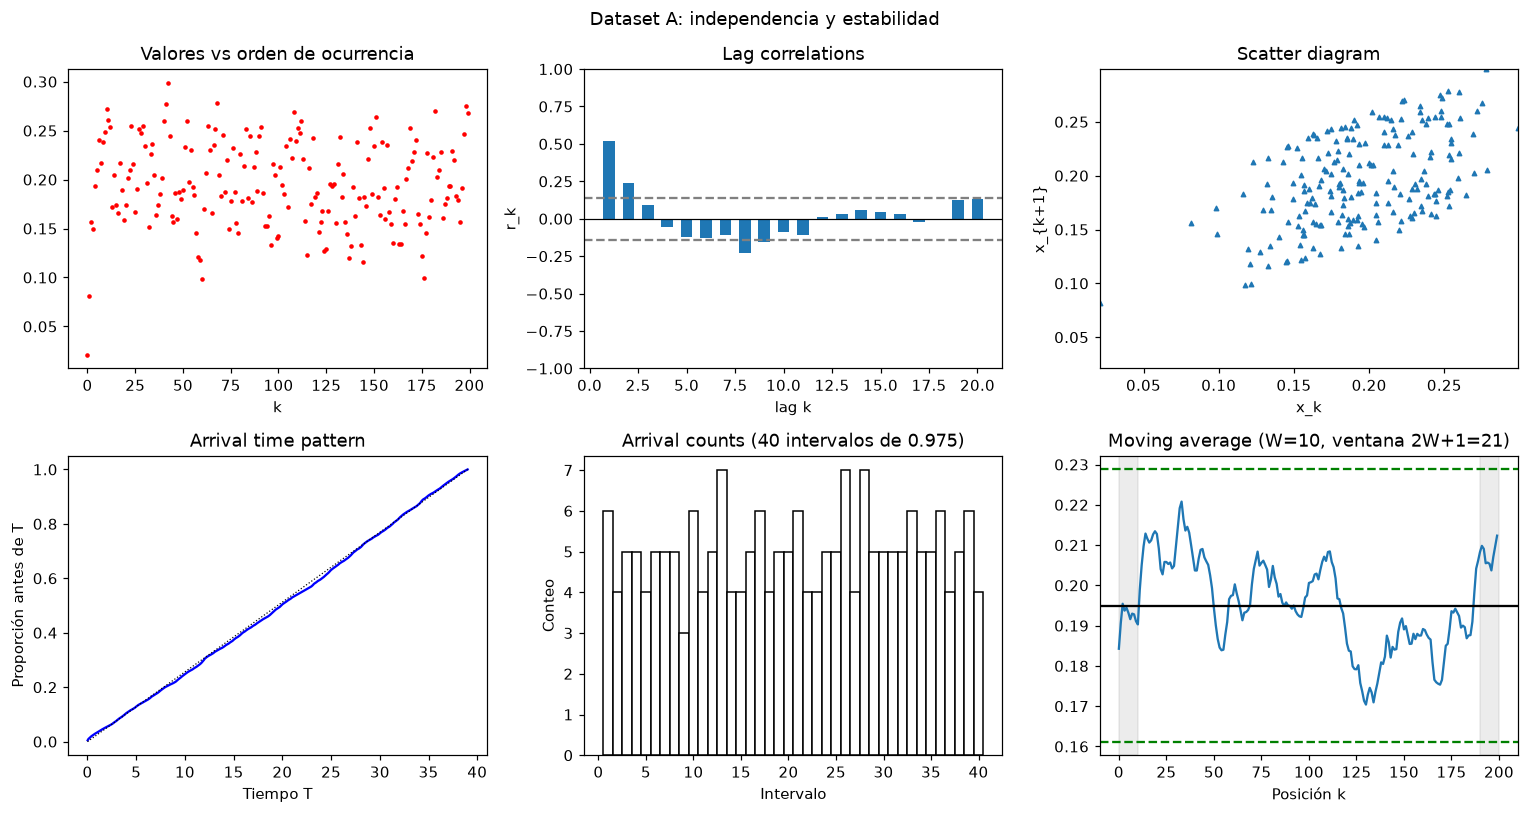

lag 1..5: [ 0.517  0.239  0.094 -0.057 -0.119] | banda ±2/sqrt(n) = 0.141


In [7]:
analisis_supuestos('A', data['A'])

**Dataset A: correlacionado y estacionario.** Con n = 200, la banda aproximada del 95 % para las correlaciones es ±2/√n = ±0,141.
- *Lag correlations:* r₁ = 0,517 y r₂ = 0,239 están muy por encima de la banda y decaen con el lag, que es el patrón de un proceso
  autorregresivo. También hay correlaciones negativas fuera de la banda en los lags 8–9.
- *Scatter diagram:* la nube de (xₖ, xₖ₊₁) se inclina hacia la diagonal: a un valor alto le sigue otro alto.
- *Arrival time pattern:* prácticamente una recta, sin quiebres. La tasa de llegadas es constante.
- *Arrival counts:* entre 3 y 7 llegadas por intervalo, sin tendencia.
- *Moving average:* oscila alrededor de 0,195 (de 0,17 a 0,22) y se queda dentro de las bandas. Las oscilaciones son lentas,
  otra señal de correlación positiva, pero no hay tendencia.
- Los dos primeros valores (0,021 y 0,081) son bajos y la serie sube en pocos pasos: parece un estado inicial (*warm-up*) del proceso.

**Conclusión:** la secuencia es estable, pero **no es independiente**.

### Dataset B

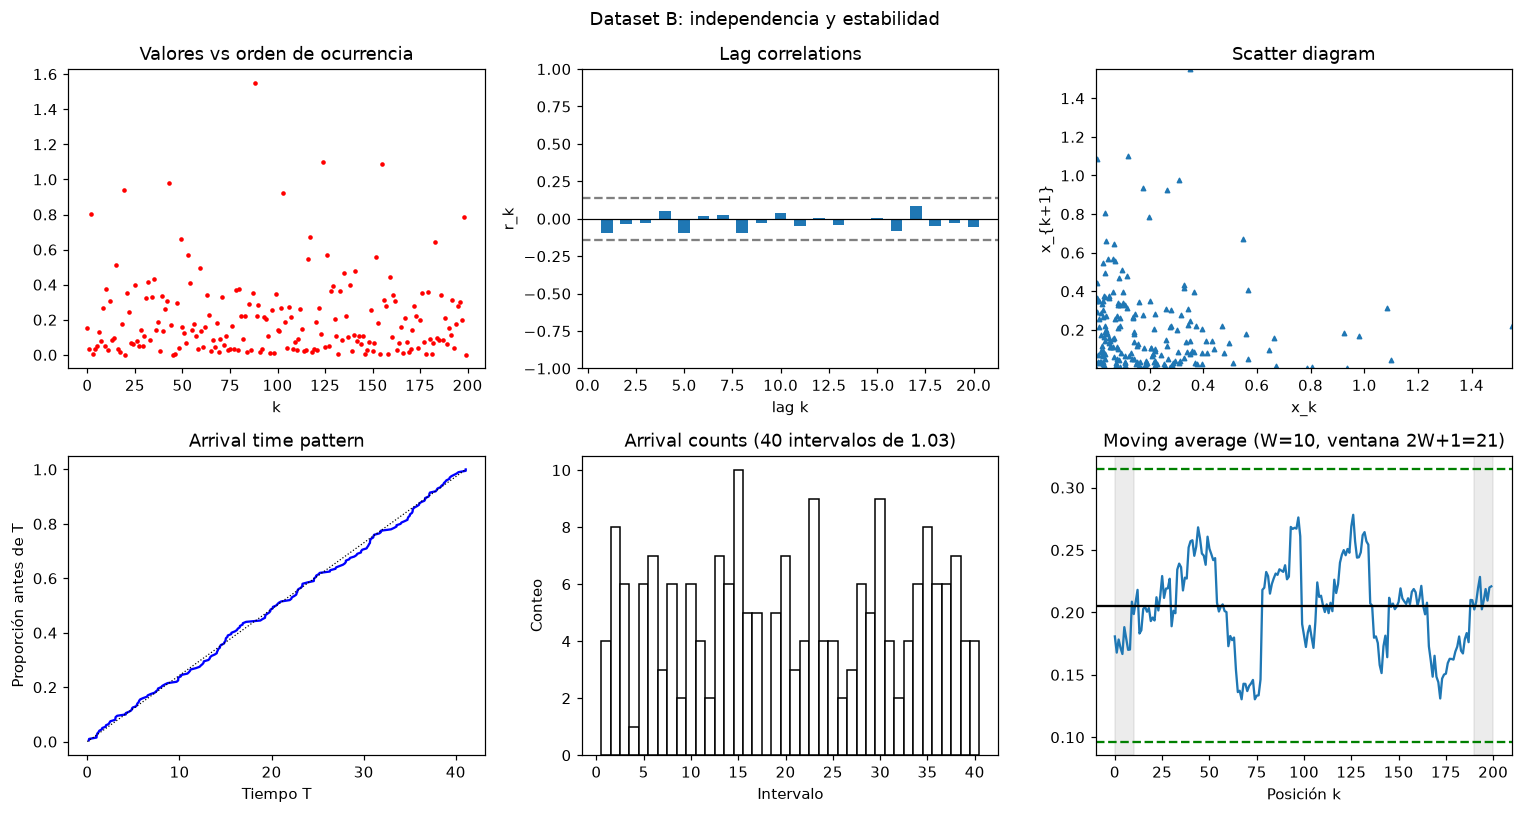

lag 1..5: [-0.093 -0.032 -0.029  0.053 -0.098] | banda ±2/sqrt(n) = 0.141


In [8]:
analisis_supuestos('B', data['B'])

**Dataset B: independiente y estacionario.** Con n = 200, la banda aproximada del 95 % para las correlaciones es ±2/√n = ±0,141.
- *Lag correlations:* todas dentro de la banda (r₁ = −0,09) y con signos alternados, sin patrón.
- *Scatter diagram:* nube concentrada cerca del origen, con la forma de la distribución marginal y sin inclinación.
- *Arrival time pattern:* sigue la diagonal con pequeñas desviaciones aleatorias.
- *Arrival counts:* entre 0 y 10 llegadas por intervalo, sin tendencia. Con media ≈ 5, esa dispersión es la esperada para conteos Poisson.
- *Moving average:* oscila entre 0,13 y 0,28 sin tendencia y siempre dentro de las bandas.

**Conclusión:** se puede tratar como **IID**. El patrón de llegadas lineal junto con la forma exponencial del histograma sugieren un proceso de Poisson.

### Dataset C

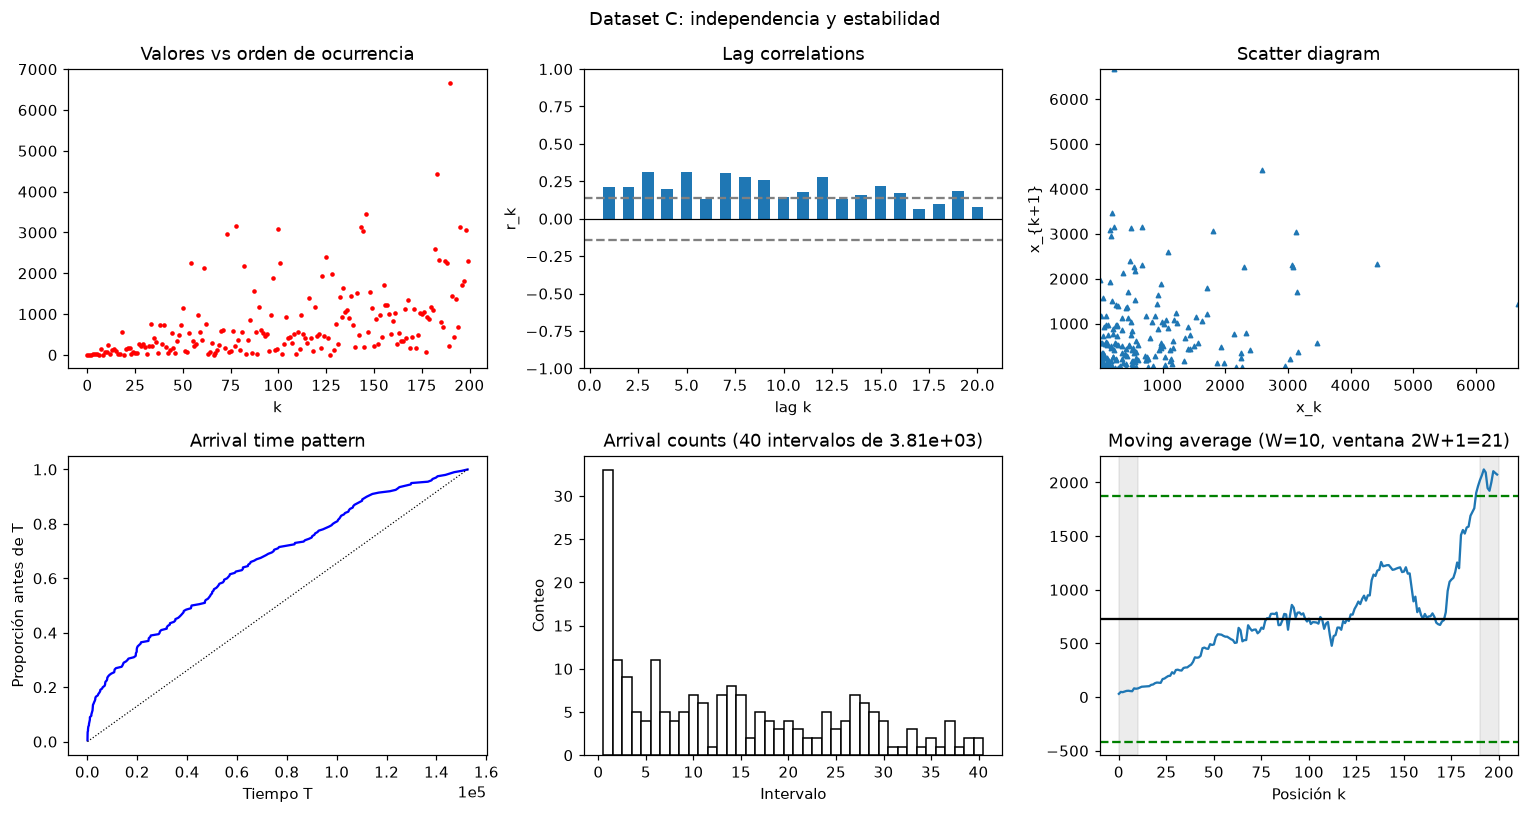

lag 1..5: [0.21  0.214 0.311 0.196 0.31 ] | banda ±2/sqrt(n) = 0.141


In [9]:
analisis_supuestos('C', data['C'])

**Dataset C: no estacionario (tendencia creciente).** Con n = 200, la banda aproximada del 95 % para las correlaciones es ±2/√n = ±0,141.
- *Valores vs orden:* los valores crecen con k. Los primeros 20 casi no pasan de 600, y los últimos llegan a miles.
- *Lag correlations:* todas positivas y por encima de la banda hasta el lag 15 aproximadamente, sin decaer.
  Una correlación que no decae es el síntoma típico de una **tendencia**, no de una dependencia de corto plazo.
- *Scatter diagram:* nube dispersa; la dependencia no se ve como en A porque la variabilidad es enorme.
- *Arrival time pattern:* curva cóncava muy alejada de la diagonal. Al principio las llegadas son rápidas
  (20 % de las llegadas en el 4 % del tiempo y la mitad en el 27 %) y luego cada vez más lentas.
- *Arrival counts:* 33 llegadas en el primer intervalo y luego 1–8: la tasa disminuye con el tiempo.
- *Moving average:* sube casi sin pausa, de ≈30 a ≈2100, y se sale de las bandas al final.

**Conclusión:** la distribución **no es estable**. La media por bloques de 50 datos crece de 191 a 1251.
Ajustar una sola distribución a todos los datos mezcla escalas distintas (ver 5.3).

### Dataset D

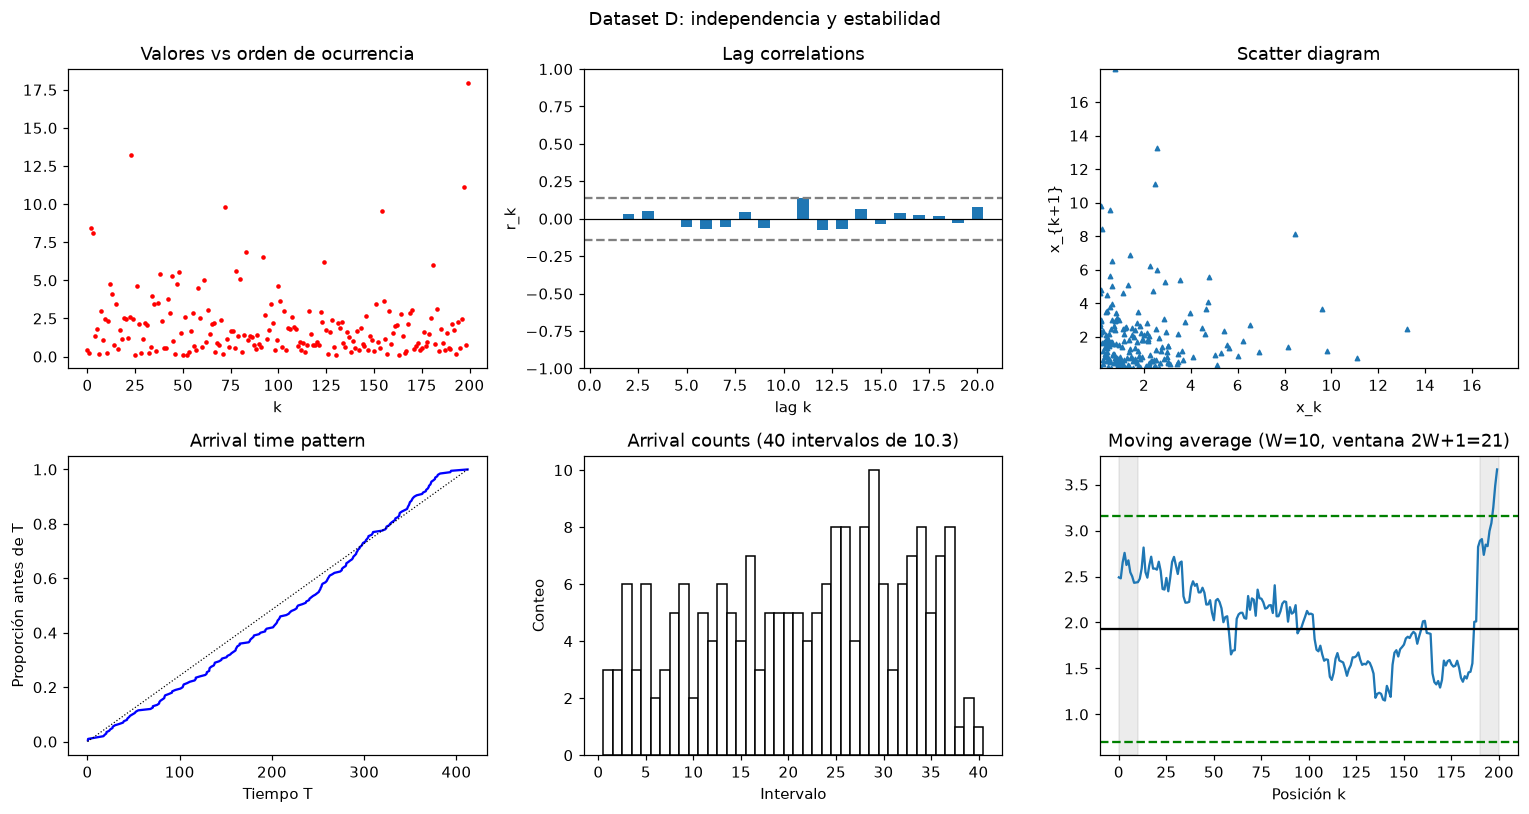

lag 1..5: [-0.003  0.035  0.053  0.002 -0.056] | banda ±2/sqrt(n) = 0.141


In [10]:
analisis_supuestos('D', data['D'])

**Dataset D: independiente; estacionariedad aceptable con una leve deriva.** Con n = 200, la banda aproximada del 95 % para las correlaciones es ±2/√n = ±0,141.
- *Lag correlations:* todas dentro de la banda (r₁ = −0,003), sin patrón.
- *Scatter diagram:* nube sin inclinación, concentrada cerca del origen.
- *Arrival time pattern:* cerca de la diagonal. En la primera mitad queda un poco por debajo (llegadas algo más lentas) y luego la cruza.
- *Arrival counts:* de 2 a 10 por intervalo, algo más altos entre los intervalos 25 y 37. Los tres últimos tienen solo 1–2 llegadas
  porque dos de los últimos tres valores son grandes (11,1 y 18,0).
- *Moving average:* baja suavemente de ≈2,6 a ≈1,5 y sube al final. Solo se sale de la banda en la zona sombreada del borde,
  donde se promedian menos datos y pesan esos dos valores extremos.

**Conclusión:** los datos son **independientes**. La leve deriva de la media no es significativa (Spearman p = 0,10,
Kruskal-Wallis p = 0,24), así que **D se acepta como IID**, aunque conviene vigilar la estabilidad si se toman más datos.

### Pruebas numéricas de apoyo
Las gráficas se complementan con pruebas formales (nivel 5 %):
- **Ljung-Box** con 10 lags: H0 = no hay autocorrelación en los lags 1–10.
- **Rachas** por encima/debajo de la mediana: H0 = la secuencia es aleatoria.
- **Spearman (valor vs. orden)**: H0 = no hay tendencia monótona en el tiempo.
- **Kruskal-Wallis** entre 4 bloques consecutivos de 50 datos: H0 = los bloques vienen de la misma distribución (estabilidad).

In [11]:
def ljung_box(x, m=10):
    n = len(x)
    q = n * (n + 2) * sum(lag_corr(x, j) ** 2 / (n - j) for j in range(1, m + 1))
    return q, st.chi2.sf(q, m)

def rachas(x):
    s = x > np.median(x); n = len(s); n1 = s.sum(); n2 = n - n1
    r = 1 + np.sum(s[1:] != s[:-1])
    mu = 2 * n1 * n2 / n + 1
    var = 2 * n1 * n2 * (2 * n1 * n2 - n) / (n ** 2 * (n - 1))
    z = (r - mu) / np.sqrt(var)
    return z, 2 * st.norm.sf(abs(z))

filas = []
for k, x in data.items():
    q, pq = ljung_box(x)
    z, pz = rachas(x)
    sp = st.spearmanr(np.arange(len(x)), x)
    kw = st.kruskal(*np.array_split(x, 4))
    filas.append({'Dataset': k, 'r_1': lag_corr(x, 1), 'Ljung-Box Q(10)': q, 'p LB': pq,
                  'Rachas z': z, 'p rachas': pz, 'Spearman rho': sp.statistic, 'p Spearman': sp.pvalue,
                  'p Kruskal-Wallis': kw.pvalue,
                  'Medias por bloque': ', '.join(f'{b.mean():.4g}'for b in np.array_split(x, 4))})
pruebas = pd.DataFrame(filas).set_index('Dataset')

with open(TAB / 'tabla_pruebas.tex', 'w', encoding='utf-8') as f:
    for k, r in pruebas.iterrows():
        f.write(f'{k} & ' + ' & '.join(num_tex(r[c], 3) for c in
                ['r_1', 'p LB', 'p rachas', 'Spearman rho', 'p Spearman', 'p Kruskal-Wallis'])
                + ' & ' + r['Medias por bloque'].replace('.', '{,}').replace(', ', '; ') + ' \\\\\n')
pruebas.style.format({c: '{:.3g}' for c in pruebas.columns if c != 'Medias por bloque'})

,r_1,Ljung-Box Q(10),p LB,Rachas z,p rachas,Spearman rho,p Spearman,p Kruskal-Wallis,Medias por bloque
Dataset,,,,,,,,,
A,0.517,95.2,4.99e-16,-3.26,0.00111,-0.105,0.14,0.394,"0.2015, 0.196, 0.189, 0.1937"
B,-0.0925,7.41,0.686,2.13,0.0334,-0.00348,0.961,0.989,"0.2172, 0.1927, 0.2109, 0.2008"
C,0.21,124,6.56e-22,-2.41,0.0159,0.603,3.21e-21,7.96e-14,"191, 644.1, 963.6, 1251"
D,-0.00259,4.32,0.932,1.28,0.202,-0.117,0.0987,0.242,"2.585, 1.981, 1.52, 2.156"


### Resumen de 5.2
| Dataset | Independencia | Estabilidad | ¿IID? |
|---|---|---|---|
| A | **No**: r₁ = 0,52, Ljung-Box p ≈ 0, rachas p = 0,001 | Sí: sin tendencia (Spearman p = 0,14, K-W p = 0,39) | **No** (correlacionado) |
| B | Sí: Ljung-Box p = 0,69 | Sí: Spearman p = 0,96, K-W p = 0,99 | **Sí** |
| C | No: Ljung-Box p ≈ 0 (efecto de la tendencia) | **No**: Spearman ρ = 0,60, p ≈ 0; medias por bloque 191 → 1251 | **No** (no estacionario) |
| D | Sí: Ljung-Box p = 0,93 | Sí (deriva leve no significativa: Spearman p = 0,10) | **Sí** |

La prueba de rachas de B da p = 0,033: hay un poco más de rachas de las esperadas, pero ninguna correlación sale de la banda
y Ljung-Box no rechaza. Se considera un resultado aislado (con 4 pruebas por dataset al 5 %, alguna puede rechazar por azar).

Solo B y D cumplen los supuestos para ajustar directamente una distribución univariada IID. Para A y C, el ajuste de 5.3 describe
la distribución *marginal* agregada, y hay que complementarlo con un modelo de la dependencia o de la tendencia (Banks, sección 3.6).